In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import warnings
warnings.filterwarnings('ignore')

In [3]:
#load the dataset from local CSV
df = pd.read_csv('bank-full.csv', sep=';')
df['target'] = (df['y'] == 'yes').astype(int)

In [4]:
#leakage type 1: train-test contamination (data overlap)
X_contam = df[['age', 'job', 'marital', 'education', 'housing', 'loan', 'poutcome']]
y_contam = df['target']

X_train_clean, X_test, y_train_clean, y_test = train_test_split(X_contam, y_contam, test_size=0.3, random_state=42)

#tHE LEAKAGE,accidentally append the test data into the training data.
X_train_leaked = pd.concat([X_train_clean, X_test])
y_train_leaked = pd.concat([y_train_clean, y_test])

preprocessor_contam = ColumnTransformer([
    ('num', StandardScaler(), ['age']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['job', 'marital', 'education', 'housing', 'loan', 'poutcome'])
])

model_contam = Pipeline([
    ('preprocessor', preprocessor_contam),
    ('classifier', DecisionTreeClassifier(criterion='entropy', random_state=42))
])

model_contam.fit(X_train_leaked, y_train_leaked)
y_pred_contam = model_contam.predict(X_test)

acc_contam = accuracy_score(y_test, y_pred_contam)
prec_contam = precision_score(y_test, y_pred_contam)
rec_contam = recall_score(y_test, y_pred_contam)
f1_contam = f1_score(y_test, y_pred_contam)

print("--- TRAIN-TEST CONTAMINATION RESULTS ---")
print(classification_report(y_test, y_pred_contam))

--- TRAIN-TEST CONTAMINATION RESULTS ---
              precision    recall  f1-score   support

           0       0.93      1.00      0.96     10968
           1       0.96      0.41      0.57      1389

    accuracy                           0.93     12357
   macro avg       0.95      0.70      0.77     12357
weighted avg       0.93      0.93      0.92     12357



In [5]:
#leakage type 2: feature leakage (future information)

#the leakage: properly isolate the train/test sets, but include 'duration'
X_feat = df[['age', 'job', 'marital', 'education', 'housing', 'loan', 'poutcome', 'duration']]
y_feat = df['target']

X_train_feat, X_test_feat, y_train_feat, y_test_feat = train_test_split(X_feat, y_feat, test_size=0.3, random_state=42)

preprocessor_feat = ColumnTransformer([
    ('num', StandardScaler(), ['age', 'duration']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['job', 'marital', 'education', 'housing', 'loan', 'poutcome'])
])

model_feat = Pipeline([
    ('preprocessor', preprocessor_feat),
    ('classifier', DecisionTreeClassifier(criterion='entropy', random_state=42))
])
model_feat.fit(X_train_feat, y_train_feat)
y_pred_feat = model_feat.predict(X_test_feat)

acc_feat = accuracy_score(y_test_feat, y_pred_feat)
prec_feat = precision_score(y_test_feat, y_pred_feat)
rec_feat = recall_score(y_test_feat, y_pred_feat)
f1_feat = f1_score(y_test_feat, y_pred_feat)

print("\n--- FEATURE LEAKAGE RESULTS ---")
print(classification_report(y_test_feat, y_pred_feat))


--- FEATURE LEAKAGE RESULTS ---
              precision    recall  f1-score   support

           0       0.92      0.91      0.92     10968
           1       0.37      0.40      0.39      1389

    accuracy                           0.86     12357
   macro avg       0.65      0.66      0.65     12357
weighted avg       0.86      0.86      0.86     12357



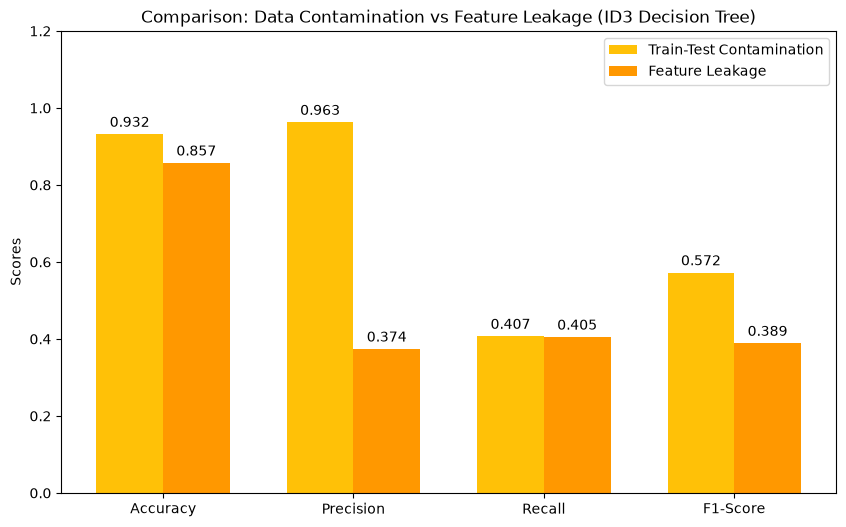

In [6]:
#graph 1: comparing the two leakages
labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
contam_scores = [acc_contam, prec_contam, rec_contam, f1_contam]
feat_scores = [acc_feat, prec_feat, rec_feat, f1_feat]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, contam_scores, width, label='Train-Test Contamination', color='#FFC107')
rects2 = ax.bar(x + width/2, feat_scores, width, label='Feature Leakage', color='#FF9800')

ax.set_ylabel('Scores')
ax.set_title('Comparison: Data Contamination vs Feature Leakage (ID3 Decision Tree)')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.2)
ax.legend()

ax.bar_label(rects1, fmt='%.3f', padding=3)
ax.bar_label(rects2, fmt='%.3f', padding=3)
plt.show()

In [ ]:
#leakage type 3: combined leakage (contamination + feature leakage)

#the leakage: combine both mistakes. include 'duration' and we overlap the train/test sets.

X_combined = df[['age', 'job', 'marital', 'education', 'housing', 'loan', 'poutcome', 'duration']]
y_combined = df['target']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_combined, y_combined, test_size=0.3, random_state=42)

#mistake 1: data overlap
X_train_combined_leaked = pd.concat([X_train_c, X_test_c])
y_train_combined_leaked = pd.concat([y_train_c, y_test_c])

#mistake 2: duration feature is included in the preprocessor
preprocessor_combined = ColumnTransformer([
    ('num', StandardScaler(), ['age', 'duration']),
    ('cat', OneHotEncoder(handle_unknown='ignore'), ['job', 'marital', 'education', 'housing', 'loan', 'poutcome'])
])

model_combined = Pipeline([
    ('preprocessor', preprocessor_combined),
    ('classifier', DecisionTreeClassifier(criterion='entropy', random_state=42))
])

model_combined.fit(X_train_combined_leaked, y_train_combined_leaked)
y_pred_combined = model_combined.predict(X_test_c)

acc_comb = accuracy_score(y_test_c, y_pred_combined)
prec_comb = precision_score(y_test_c, y_pred_combined)
rec_comb = recall_score(y_test_c, y_pred_combined)
f1_comb = f1_score(y_test_c, y_pred_combined)

print("\n--- COMBINED LEAKAGE RESULTS (Contamination + Feature) ---")
print(classification_report(y_test_c, y_pred_combined))


--- COMBINED LEAKAGE RESULTS (Contamination + Feature) ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10968
           1       1.00      0.99      1.00      1389

    accuracy                           1.00     12357
   macro avg       1.00      1.00      1.00     12357
weighted avg       1.00      1.00      1.00     12357



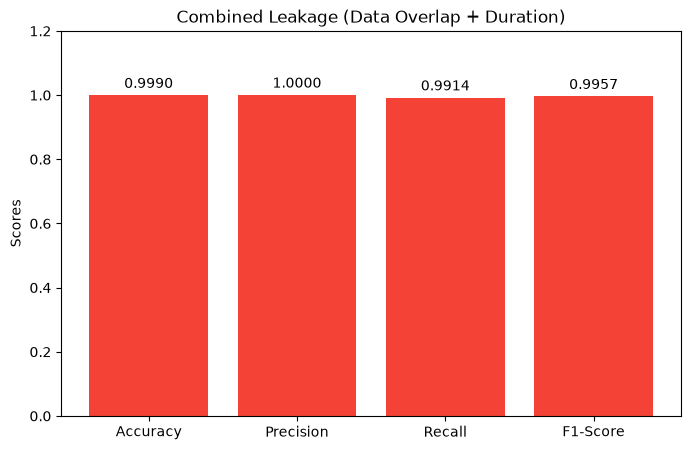

In [8]:
#graph 2: combined leakage graph

labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
combined_scores = [acc_comb, prec_comb, rec_comb, f1_comb]

x = np.arange(len(labels))

fig, ax = plt.subplots(figsize=(8, 5))
rects3 = ax.bar(labels, combined_scores, color='#F44336')

ax.set_ylabel('Scores')
ax.set_title('Combined Leakage (Data Overlap + Duration)')
ax.set_ylim(0, 1.2)

ax.bar_label(rects3, fmt='%.4f', padding=3)
plt.show()